<a href="https://colab.research.google.com/github/tejsvinimeshram/Practical/blob/main/EE524_task10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np

In [ ]:
class Layer:
  def __init__(self):
    self.input = None
    self.output = None
  def forward(self, input):
    pass
  def backward(self, output_gradient, learning_rate):
    pass

In [ ]:
class Dense(Layer):
  def __init__(self, input_size, output_size):
    self.weights = np.random.randn(output_size, input_size)
    self.bias = np.random.randn(output_size, 1)

  def forward(self, input):
    self.input = input
    return np.dot(self.weights, self.input) + self.bias

  def backward(self, output_gradient, learning_rate):
    weights_gradient = np.dot(output_gradient, self.input.T)
    input_gradient = np.dot(self.weights.T, output_gradient)
    self.weights -= learning_rate * weights_gradient
    self.bias -= learning_rate * output_gradient
    return input_gradient

In [ ]:
def mse(y_true, y_pred):
  return np.mean(np.power(y_true-y_pred, 2));
def mse_prime(y_true, y_pred):
  return 2*(y_pred-y_true)/np.size(y_true);

In [ ]:
class Activation(Layer):
  def __init__(self, activation, activation_prime):
    self.activation = activation
    self.activation_prime = activation_prime
  def forward(self, input):
    self.input = input
    return self.activation(self.input)
  def backward(self, output_gradient, learning_rate):
    return np.multiply(output_gradient, self.activation_prime(self.input))

In [ ]:
class Tanh(Activation):
  def __init__(self):
    def tanh(x):
      return np.tanh(x)
    def tanh_prime(x):
      return 1 - np.tanh(x)**2
    super().__init__(tanh, tanh_prime)

class Sigmoid(Activation):
  def __init__(self):
    def sigmoid(x):
      return 1 / (1 + np.exp(-x))
    def sigmoid_prime(x):
      s = sigmoid(x)
      return s * (1 - s)
    super().__init__(sigmoid, sigmoid_prime)

In [ ]:
import math

In [ ]:
class Linear(Activation):
  def __init__(self):
    def linear(x):
      return x
    def linear_prime(x):
      return 1
    super().__init__(linear, linear_prime)

In [ ]:
import numpy as np
x_train=np.linspace(-3,3,61)
y_train=[math.sin(p)for p in x_train]

network=[Dense(1,10),Tanh(),Dense(10,1),Linear()]

epochs=50
learning_rate=0.01
errorlist=[]

for e in range(epochs):
  error=0
  for x,y in zip(x_train,y_train):

    output=np.array([[x]])
    target=np.array([[y]])

    for layer in network:
      output=layer.forward(output)
    error+=mse(target,output)

    grad=mse_prime(target,output)
    for layer in reversed(network):
      grad=layer.backward(grad,learning_rate)
  error/=len(x_train)
  print(f"{e+1}/{epochs}, error={error}")
  errorlist.append(error)

1/50, error=0.02183594587419452
2/50, error=0.09454960337766345
3/50, error=0.05501215594299385
4/50, error=0.030915183872915537
5/50, error=0.01296079943252098
6/50, error=0.005712357112783683
7/50, error=0.003987504812634314
8/50, error=0.0036421566126630008
9/50, error=0.003171114346846645
10/50, error=0.0026346479033992625
11/50, error=0.002270722792932873
12/50, error=0.0021429626007551258
13/50, error=0.002211336228478184
14/50, error=0.0023977899716983594
15/50, error=0.002621877631571413
16/50, error=0.00282024808154031
17/50, error=0.0029527698034907623
18/50, error=0.003002474845229837
19/50, error=0.0029705596788204653
20/50, error=0.002870076544971716
21/50, error=0.0027197436396401947
22/50, error=0.0025391140651014137
23/50, error=0.0023453886923192617
24/50, error=0.0021518301457117794
25/50, error=0.0019674209818056378
26/50, error=0.0017973291047030963
27/50, error=0.001643759617862914
28/50, error=0.0015068790541693817
29/50, error=0.001385624026924017
30/50, error=0.

In [ ]:
actual_y=[]
for x in x_train:
  output=np.array([[x]])
  for layer in network:
    output=layer.forward(output)
  actual_y.append(output[0,0])
print(actual_y)

[np.float64(-0.2325727981048021), np.float64(-0.32583103787236456), np.float64(-0.41381398048275086), np.float64(-0.49600279261643376), np.float64(-0.5719898351910531), np.float64(-0.6414712293113335), np.float64(-0.7042344187680333), np.float64(-0.7601420436685483), np.float64(-0.809113454979356), np.float64(-0.8511051105877404), np.float64(-0.8860909558285278), np.float64(-0.9140437589869729), np.float64(-0.9349182895335723), np.float64(-0.9486372246631222), np.float64(-0.9550807624357677), np.float64(-0.9540811015600116), np.float64(-0.9454231862705132), np.float64(-0.9288533411455228), np.float64(-0.9040975171383155), np.float64(-0.8708906575180663), np.float64(-0.8290179297477757), np.float64(-0.7783669815953937), np.float64(-0.7189877420913262), np.float64(-0.6511525939904713), np.float64(-0.5754054681725691), np.float64(-0.49258480515947134), np.float64(-0.40380457734809727), np.float64(-0.310382424181877), np.float64(-0.21371646398181524), np.float64(-0.115131552768475), np.flo

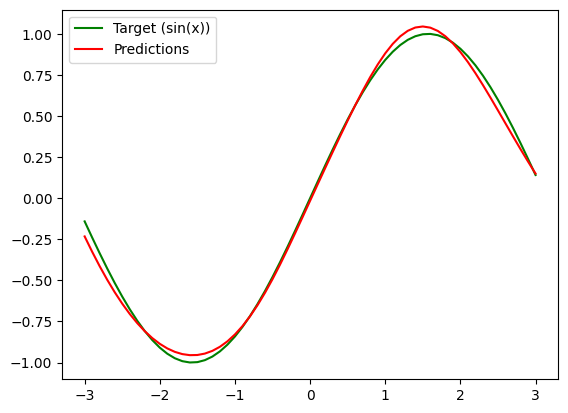

In [ ]:
import matplotlib.pyplot as plt
plt.plot(x_train, y_train, color='green', label='Target (sin(x))')
plt.plot(x_train, actual_y, color='red', label='Predictions')
plt.legend()
plt.show()